In [ ]:
# Imports and setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import GradientBoostingClassifier,HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, \
    ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

from google.colab import drive
drive.mount('/content/drive')

/usr/local/lib/python3.11/dist-packages/dask/dataframe/__init__.py:42: FutureWarning: 
Dask dataframe query planning is disabled because dask-expr is not installed.

You can install it with `pip install dask[dataframe]` or `conda install dask`.
This will raise in a future version.

  warnings.warn(msg, FutureWarning)


Mounted at /content/drive


In [ ]:
file_path2 = '/content/drive/My Drive/MyData/bank-full.csv'
df_bank_full = pd.read_csv(file_path2, delimiter=';')
print(df_bank_full.info())
print("bank-full num of records: ",df_bank_full.shape[0])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB
None
bank-full num of records:  45211


In [ ]:
file_path4 = '/content/drive/My Drive/MyData/bank-additional-full.csv'
df_bank_add_full = pd.read_csv(file_path4, delimiter=';')
print(df_bank_add_full.info())
print("bank-additional-full num of records: ",df_bank_add_full.shape[0])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [ ]:
# Check the class distribution of the target variable
class_distribution = df_bank_add_full['y'].value_counts()

scale_pos_weight = 36548/4640
print(scale_pos_weight)
print(class_distribution)

7.876724137931035
y
no     36548
yes     4640
Name: count, dtype: int64


Training our gradient boosting classifier with bank marketing dataset.


Classification Metrics:
Gradient Boosting Classifier accuracy is : 0.9030
Precision: 0.6477
Recall: 0.3733
F1-score: 0.4736


<Figure size 1000x1000 with 0 Axes>

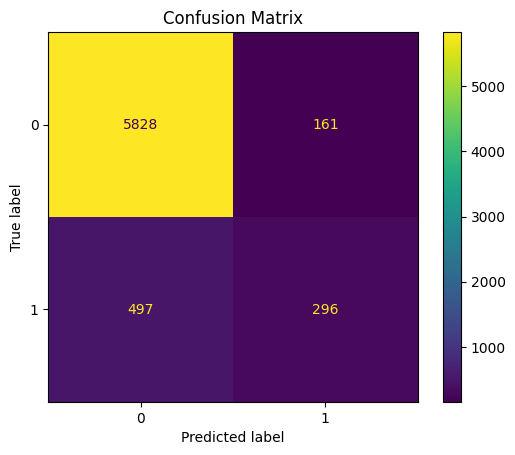

In [ ]:
# Identify the categorical columns (you can manually specify or use pd.select_dtypes)
categorical_columns = df_bank_full.select_dtypes(include=['object']).columns

# Remove the target column from the categorical columns list
categorical_columns = categorical_columns[categorical_columns != 'y']

# Apply one-hot encoding to the categorical columns
df_bank_encoded = pd.get_dummies(df_bank_full, columns=categorical_columns, drop_first=True)

X = df_bank_encoded.drop(columns='y')
y = df_bank_encoded['y']



# Splitting dataset
train_X, test_X, train_y, test_y = train_test_split(X, y,
                                                    test_size = 0.15,
                                                    stratify=y)


# Encode the labels for both train and test data
le = LabelEncoder()
train_y = le.fit_transform(train_y)
test_y = le.transform(test_y)


# Instantiate Gradient Boosting Regressor
gbc = GradientBoostingClassifier(n_estimators=300,
                                 learning_rate=0.05,
                                 random_state=42,      # For reproducibility
                                 max_features=5 )

# Fit to training set
gbc.fit(train_X, train_y)

# Predict on test set
pred_y = gbc.predict(test_X)

# accuracy
acc = accuracy_score(test_y, pred_y)
precision = precision_score(test_y, pred_y, average='binary')
recall = recall_score(test_y, pred_y, average='binary')
f1 = f1_score(test_y, pred_y, average='binary')
print("\nClassification Metrics:")
print("Gradient Boosting Classifier accuracy is : {:.4f}".format(acc))
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")
cm = confusion_matrix(test_y, pred_y)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
plt.figure(figsize=(10, 10))
disp.plot()
plt.title('Confusion Matrix')
plt.show()

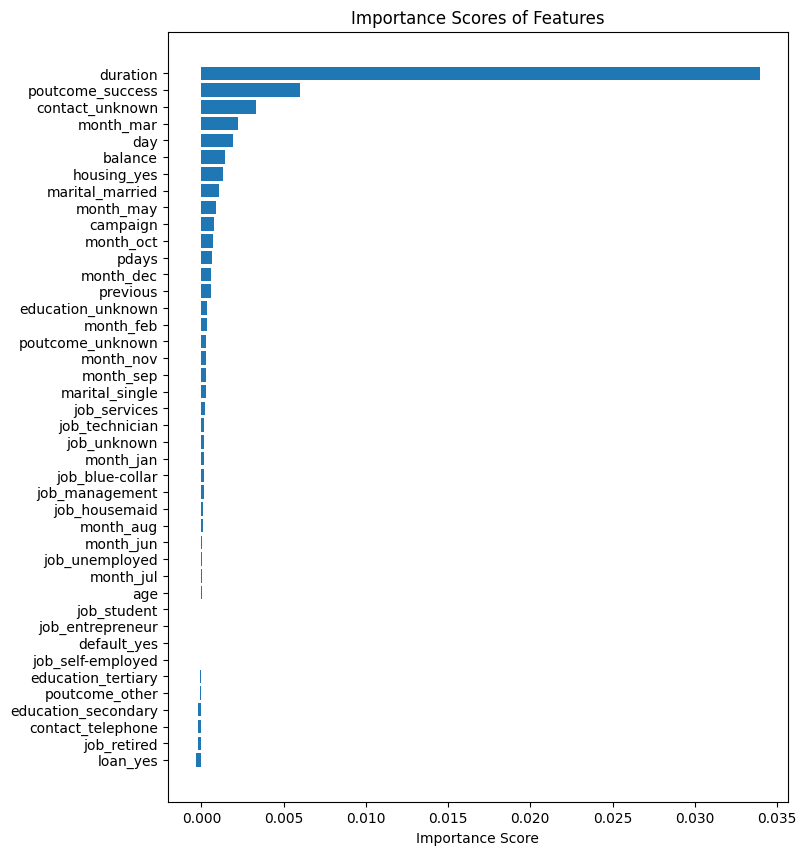

In [ ]:
# Calculate permutation importance
results = permutation_importance(gbc, test_X, test_y, n_repeats=10, random_state=42)

# Get the importance scores for each feature
importance_scores = results.importances_mean

# Sort the importance scores in descending order
sorted_idx = importance_scores.argsort()

# Create a horizontal bar plot
plt.figure(figsize=(8, 10))
plt.barh(range(len(importance_scores)), importance_scores[sorted_idx], align="center")
plt.yticks(range(len(importance_scores)), X.columns[sorted_idx])
plt.xlabel("Importance Score")
plt.title("Importance Scores of Features ")
plt.show()

Training Gradient boosting classifier using bank marketing dataset with additional features


Classification Metrics:
Gradient Boosting Classifier accuracy is : 0.9149
Precision: 0.6872
Recall: 0.4483
F1-score: 0.5426


<Figure size 1000x1000 with 0 Axes>

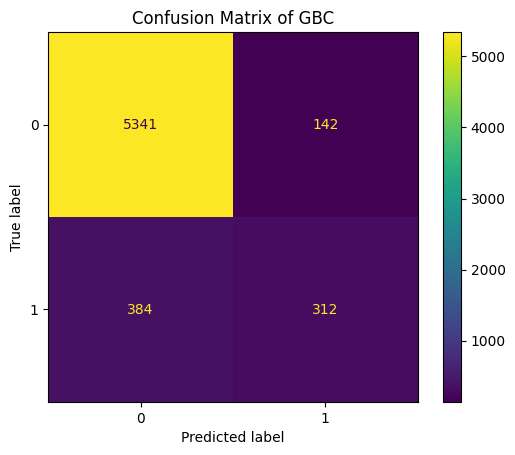

In [ ]:
# Identify the categorical columns (you can manually specify or use pd.select_dtypes)
categorical_columns = df_bank_add_full.select_dtypes(include=['object']).columns

# Remove the target column from the categorical columns list
categorical_columns = categorical_columns[categorical_columns != 'y']

# Apply one-hot encoding to the categorical columns
df_bank_add_encoded = pd.get_dummies(df_bank_add_full, columns=categorical_columns, drop_first=True)

X = df_bank_add_encoded.drop(columns='y')
y = df_bank_add_encoded['y']

# Splitting dataset
train_X, test_X, train_y, test_y = train_test_split(X, y,
                                                    test_size = 0.15,
                                                    stratify=y)


# Encode the labels for both train and test data
le = LabelEncoder()
train_y = le.fit_transform(train_y)
test_y = le.transform(test_y)

# Instantiate Gradient Boosting Classifier
gbc2 = GradientBoostingClassifier(n_estimators=300, #number of boosting stage(tree)
                                 learning_rate=0.05, #Learning rate to control contribution of each tree
                                 random_state=42,    #for reproducibility
                                 max_features=5) #maximum number of features decision treee can use at each split

# Fit to training set
gbc2.fit(train_X, train_y)

# Predict on test set
pred_y = gbc2.predict(test_X)

# accuracy
acc_gbc = accuracy_score(test_y, pred_y)
precision_gbc = precision_score(test_y, pred_y, average='binary')
recall_gbc = recall_score(test_y, pred_y, average='binary')
f1_gbc = f1_score(test_y, pred_y, average='binary')
print("\nClassification Metrics:")
print("Gradient Boosting Classifier accuracy is : {:.4f}".format(acc_gbc))
print(f"Precision: {precision_gbc:.4f}")
print(f"Recall: {recall_gbc:.4f}")
print(f"F1-score: {f1_gbc:.4f}")
cm = confusion_matrix(test_y, pred_y)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
plt.figure(figsize=(10, 10))
disp.plot()
plt.title('Confusion Matrix of GBC')
plt.show()

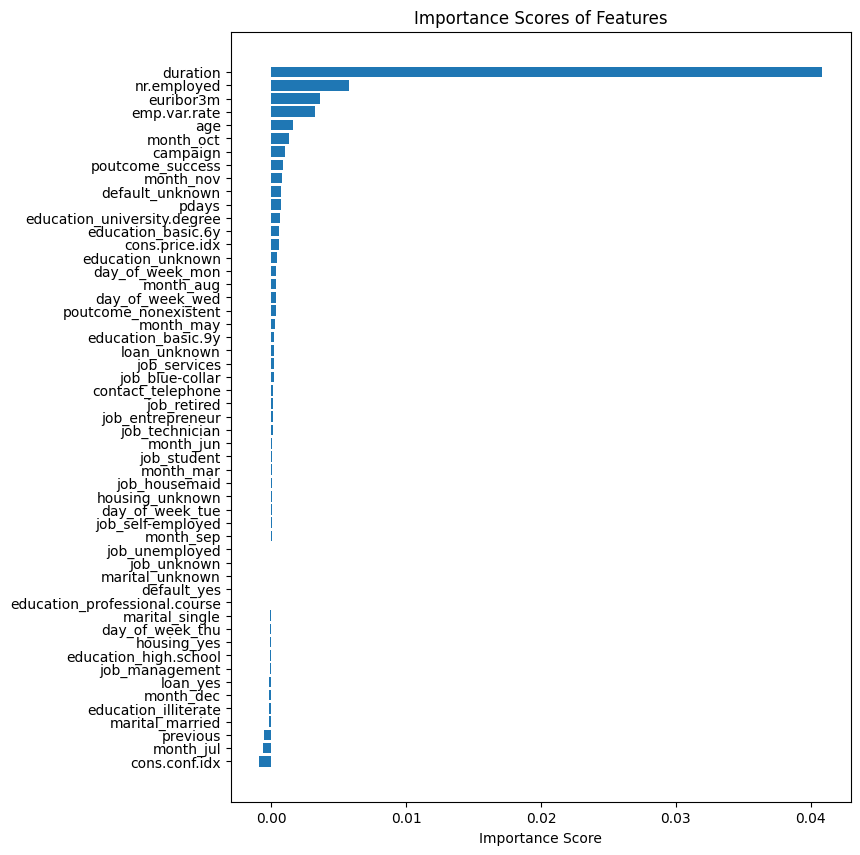

In [ ]:
# Calculate permutation importance
results = permutation_importance(gbc2, test_X, test_y, n_repeats=10, random_state=42)

# Get the importance scores for each feature
importance_scores = results.importances_mean

# Sort the importance scores in descending order
sorted_idx = importance_scores.argsort()

# Create a horizontal bar plot
plt.figure(figsize=(8, 10))
plt.barh(range(len(importance_scores)), importance_scores[sorted_idx], align="center")
plt.yticks(range(len(importance_scores)), X.columns[sorted_idx])
plt.xlabel("Importance Score")
plt.title("Importance Scores of Features")
plt.show()

Training Light gradient boosting machine using bank marketing dataset with additional features

[LightGBM] [Info] Number of positive: 3944, number of negative: 31065
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.042303 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 756
[LightGBM] [Info] Number of data points in the train set: 35009, number of used features: 51
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.112657 -> initscore=-2.063886
[LightGBM] [Info] Start training from score -2.063886

Classification Metrics:
Light Gradient Boosting Classifier accuracy is : 0.8958
Precision: 0.5222
Recall: 0.8793
F1-score: 0.6552


<Figure size 1000x1000 with 0 Axes>

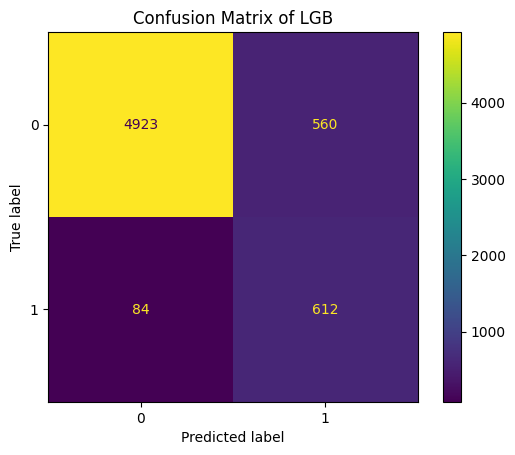

In [ ]:
#Instantiate Light Gradient Boosting Machine Classifier
lgb = LGBMClassifier(max_bin=255,  #Maximum number of bins that can be used to bucket continuos features
                    n_estimators=100, #Number of boosting rounds(tree))
                    scale_pos_weight=4, #Deal with imbalanced dataset
                     random_state=42,      # For reproducibility
                     metric ='aucpr') #Evaluation metric set to Area under curve

lgb.fit(train_X, train_y)

# Predict on test set
pred_y = lgb.predict(test_X)

# accuracy
acc_lgb = accuracy_score(test_y, pred_y)
precision_lgb = precision_score(test_y, pred_y, average='binary')
recall_lgb = recall_score(test_y, pred_y, average='binary')
f1_lgb = f1_score(test_y, pred_y, average='binary')
print("\nClassification Metrics:")
print("Light Gradient Boosting Classifier accuracy is : {:.4f}".format(acc_lgb))
print(f"Precision: {precision_lgb:.4f}")
print(f"Recall: {recall_lgb:.4f}")
print(f"F1-score: {f1_lgb:.4f}")
cm = confusion_matrix(test_y, pred_y)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
plt.figure(figsize=(10, 10))
disp.plot()
plt.title('Confusion Matrix of LGB')
plt.show()

Histogram based gradient boosting classifiction tree


Classification Metrics:
Histogram Gradient Boosting Classifier accuracy is : 0.8503
Precision: 0.4260
Recall: 0.9468
F1-score: 0.5876


<Figure size 1000x1000 with 0 Axes>

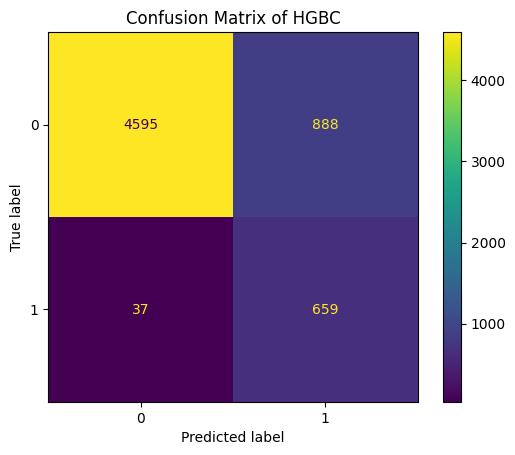

In [ ]:
# Instantiate Histogram Gradient Boosting Classifier
hgbc = HistGradientBoostingClassifier(
    max_iter=300,         # Number of boosting iterations (trees)
    learning_rate=0.05,    # Learning rate to control the contribution of each tree
    max_depth=3,          # Maximum depth of the trees
    random_state=42,      # For reproducibility
    class_weight='balanced') #To handle imbalanced dataset


# Fit to training set
hgbc.fit(train_X, train_y)

# Predict on test set
pred_y = hgbc.predict(test_X)

# accuracy
acc_hgbc = accuracy_score(test_y, pred_y)
precision_hgbc = precision_score(test_y, pred_y, average='binary')
recall_hgbc = recall_score(test_y, pred_y, average='binary')
f1_hgbc = f1_score(test_y, pred_y, average='binary')
print("\nClassification Metrics:")
print("Histogram Gradient Boosting Classifier accuracy is : {:.4f}".format(acc_hgbc))
print(f"Precision: {precision_hgbc:.4f}")
print(f"Recall: {recall_hgbc:.4f}")
print(f"F1-score: {f1_hgbc:.4f}")
cm = confusion_matrix(test_y, pred_y)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
plt.figure(figsize=(10, 10))
disp.plot()
plt.title('Confusion Matrix of HGBC')
plt.show()


Classification Metrics:
XGBoost Classifier accuracy is: 0.9158
Precision: 0.6023
Recall: 0.7443
F1-score: 0.6658


<Figure size 1000x1000 with 0 Axes>

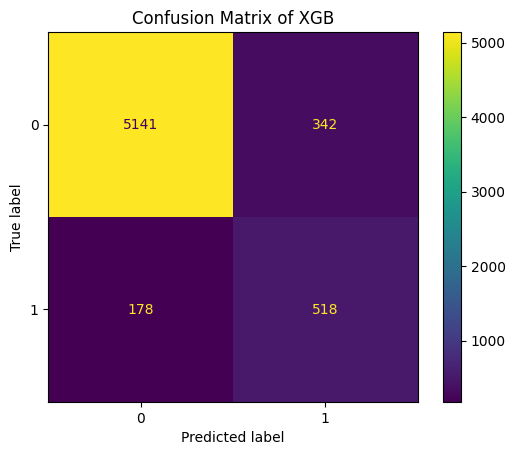

In [ ]:
# Initialize the XGBoost Classifier
xgb = XGBClassifier(tree_method='approx', #Approximate tree algorithm that is faster but less accurate
                    max_bin=255,  #Maximum number of bins that can be used to bucket continuos features
                    n_estimators=300,#Number of boosting rounds(tree)
                    scale_pos_weight=2,#Deal with imbalanced dataset
                    learning_rate=0.05, #Learning rate to control contribution of each tree
                    random_state=42,      # For reproducibility
                    eval_metric="aucpr") #Evaluation metrics set to area under curve

# Fit the model on training data
xgb.fit(train_X, train_y)

# Predict on test set
pred_y = xgb.predict(test_X)

# Compute classification metrics
acc_xgb = accuracy_score(test_y, pred_y)
precision_xgb = precision_score(test_y, pred_y, average='binary')
recall_xgb = recall_score(test_y, pred_y, average='binary')
f1_xgb = f1_score(test_y, pred_y, average='binary')

# Print classification metrics
print("\nClassification Metrics:")
print(f"XGBoost Classifier accuracy is: {acc_xgb:.4f}")
print(f"Precision: {precision_xgb:.4f}")
print(f"Recall: {recall_xgb:.4f}")
print(f"F1-score: {f1_xgb:.4f}")

# Confusion Matrix
cm = confusion_matrix(test_y, pred_y)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)

# Plot the confusion matrix
plt.figure(figsize=(10, 10))
disp.plot()
plt.title('Confusion Matrix of XGB')
plt.show()

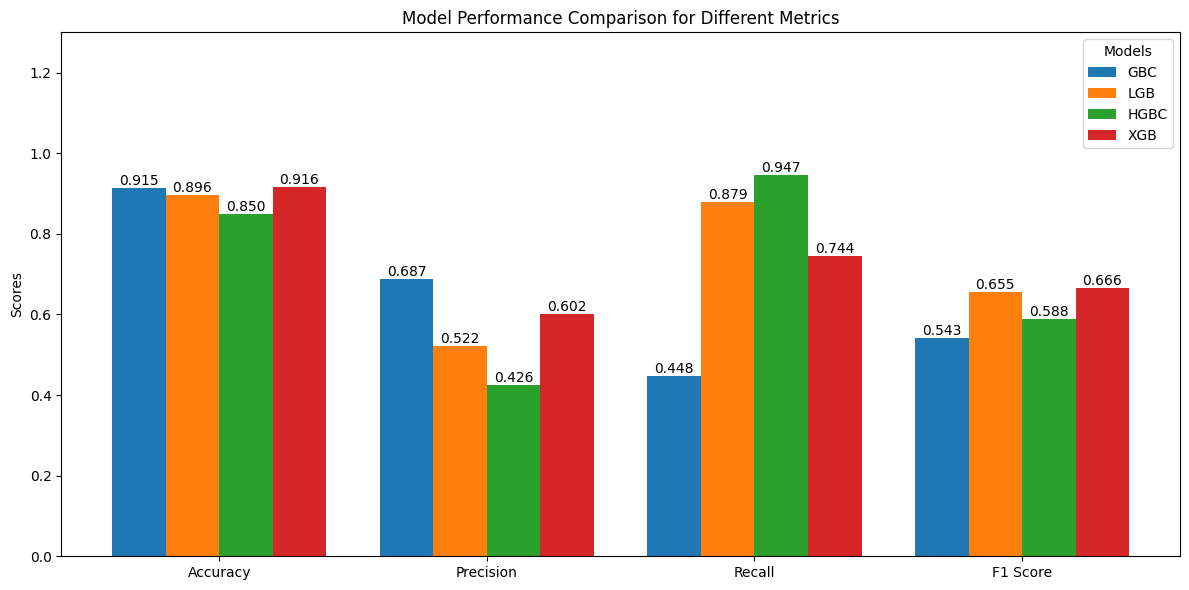

In [ ]:
# Models and their respective scores
models = ['GBC', 'LGB', 'HGBC', 'XGB']
accuracy = [acc_gbc, acc_lgb, acc_hgbc, acc_xgb]
precision = [precision_gbc, precision_lgb, precision_hgbc, precision_xgb]
recall = [recall_gbc, recall_lgb, recall_hgbc, recall_xgb]
f1 = [f1_gbc, f1_lgb, f1_hgbc, f1_xgb]

# Metrics
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']

# Organize the scores for each metric in the same order
scores = [accuracy, precision, recall, f1]

# Number of models
num_models = len(models)

# Positioning for the bars
x = np.arange(len(metrics))  # positions for each metric
width = 0.2  # bar width (adjusted for 4 models)

# Plot bars for each model
fig, ax = plt.subplots(figsize=(12, 6))  # Adjusted width for better spacing

# Colors for each model (GBC, LGB, HGBC, XGB)
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']  # Added color for XGB

# Loop over each model and plot each model's bars for the four metrics
for i, model in enumerate(models):
    ax.bar(x + (i - 1.5) * width, [scores[j][i] for j in range(len(metrics))], width, label=model, color=colors[i])

# Add numbers on top of each bar
for i in range(len(metrics)):
    for j in range(num_models):
        yval = scores[i][j]
        ax.text(x[i] + (j - 1.5) * width, yval, f'{yval:.3f}', ha='center', va='bottom')

# Set y-axis range
ax.set_ylim(0, 1.3)

# Adding labels and title
ax.set_ylabel('Scores')
ax.set_title('Model Performance Comparison for Different Metrics')
ax.set_xticks(x)
ax.set_xticklabels(metrics)

# Adding a legend with only model labels
ax.legend(title="Models")

# Show plot
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

# Instantiate Gradient Boosting Classifier
gbc2 = GradientBoostingClassifier(n_estimators = 300,  #number of boosting stage(tree)
                                 learning_rate = 0.05, #Learning rate to control contribution of each tree
                                 random_state = 42,   #for reproducibility
                                 max_features = 5) #maximum number of features decision treee can use at each split


from sklearn.ensemble import HistGradientBoostingClassifier

# Instantiate Histogram Gradient Boosting Classifier
hgbc = HistGradientBoostingClassifier(
    max_iter = 300,       # Number of boosting iterations (trees)
    learning_rate = 0.05, # Learning rate to control the contribution of each tree
    max_depth = 3,          # Maximum depth of the trees
    random_state = 42,      # For reproducibility
    class_weight = 'balanced') #To handle imbalanced dataset


from lightgbm import LGBMClassifier

#Instantiate Light Gradient Boosting Machine Classifier
lgb = LGBMClassifier(max_bin = 255,  #Maximum number of bins that can be used to bucket continuous features
                    n_estimators = 100,   #Number of boosting rounds(tree))
                    scale_pos_weight = 2, #Deal with imbalanced dataset
                     random_state=42,      # For reproducibility
                     metric = 'auc')      #Evaluation metric set to Area under curve


from xgboost import XGBClassifier

# Initialize the XGBoost Classifier
xgb = XGBClassifier(tree_method='approx', #Approximate tree algorithm that is faster but less accurate
                    max_bin=255,  #Maximum number of bins that can be used to bucket continuos features
                    n_estimators=300,#Number of boosting rounds(tree)
                    scale_pos_weight=2,#Deal with imbalanced dataset
                    random_state=42,      # For reproducibility
                    learning_rate=0.05, #Learning rate to control contribution of each tree
                    eval_metric="aucpr") #Evaluation metrics set to area under curve

Fine tuning with hyperparameters using GridSearchCV

In [ ]:
# Define hyperparameter grids
param_grids = {
    'GBC': {
        'n_estimators': [100, 300, 500],
        'learning_rate': [0.01, 0.05, 0.1],
        'max_depth': [3, 5, 7],
        'max_features': ['sqrt', 'log2']
    },
    'LGB': {
        'n_estimators': [100, 300, 500],
        'learning_rate': [0.01, 0.05, 0.1],
        'max_depth': [3, 5, 7],
        'scale_pos_weight': [1, 2, 3, 4]
    },
    'HGBC': {
        'max_iter': [100, 300, 500],
        'learning_rate': [0.01, 0.05, 0.1],
        'max_depth': [3, 5, 7],
        'class_weight': ['balanced', None]
    },
    'XGB': {
        'n_estimators': [100, 300, 500],
        'learning_rate': [0.01, 0.05, 0.1],
        'max_depth': [3, 5, 7],
        'scale_pos_weight': [1, 2, 3, 4]
    }
}

# Define classifiers
models = {
    'GBC': GradientBoostingClassifier(random_state=42),
    'LGB': LGBMClassifier(metric='auc', random_state=42),
    'HGBC': HistGradientBoostingClassifier(random_state=42),
    'XGB': XGBClassifier(eval_metric='aucpr', random_state=42)
}

# Store results
best_params = {}
metrics = {'accuracy': [], 'precision': [], 'recall': [], 'f1': []}

# Run GridSearchCV and evaluate models
for name, model in models.items():
    print(f"Running GridSearchCV for {name}...")
    grid_search = GridSearchCV(model, param_grids[name], scoring='f1', cv=3, n_jobs=-1, verbose=1) # i set cv to 3 because it takes a long time to run
    grid_search.fit(train_X, train_y)
    best_params[name] = grid_search.best_params_
    print(f"Best params for {name}: {grid_search.best_params_}")

    # Evaluate on test set
    best_model = grid_search.best_estimator_
    pred_y = best_model.predict(test_X)

    metrics['accuracy'].append(accuracy_score(test_y, pred_y))
    metrics['precision'].append(precision_score(test_y, pred_y))
    metrics['recall'].append(recall_score(test_y, pred_y))
    metrics['f1'].append(f1_score(test_y, pred_y))

Running GridSearchCV for GBC...
Fitting 3 folds for each of 54 candidates, totalling 162 fits
Best params for GBC: {'learning_rate': 0.05, 'max_depth': 7, 'max_features': 'sqrt', 'n_estimators': 300}
Running GridSearchCV for LGB...
Fitting 3 folds for each of 108 candidates, totalling 324 fits
[LightGBM] [Info] Number of positive: 3944, number of negative: 31065
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.008889 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 756
[LightGBM] [Info] Number of data points in the train set: 35009, number of used features: 51
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.112657 -> initscore=-2.063886
[LightGBM] [Info] Start training from score -2.063886
Best params for LGB: {'learning_rate': 0.05, 'max_depth': 7, 'n_estimators': 100, 'scale_pos_weight': 2}
Running GridSearchCV for HGBC...
Fitting 3 f

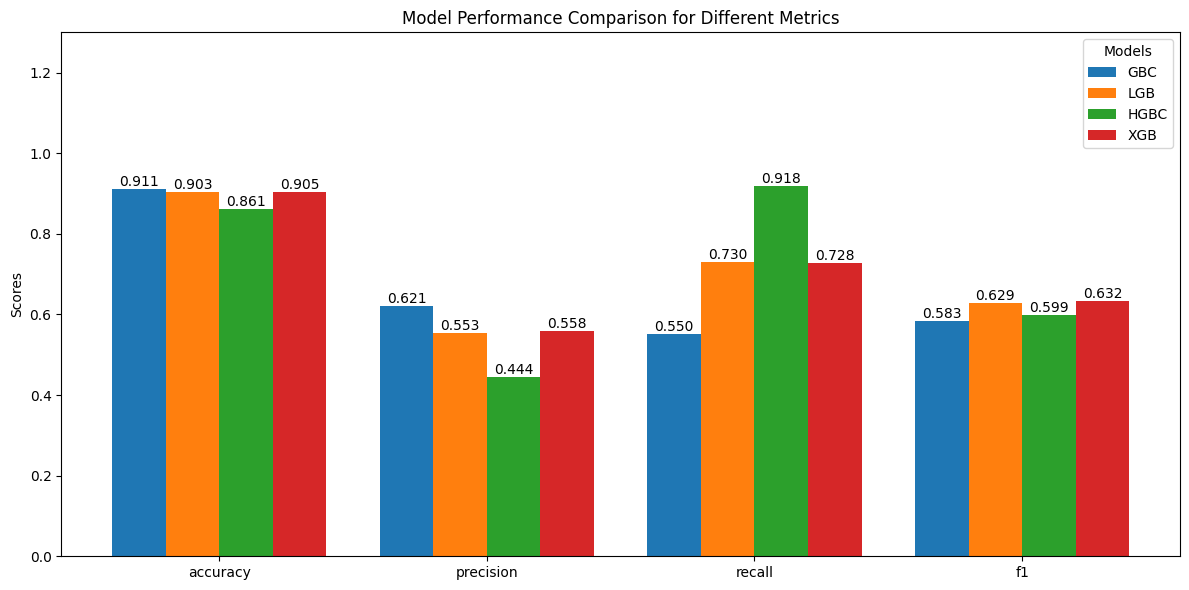

In [ ]:
# Plot bar chart
models_list = list(models.keys())
metric_names = list(metrics.keys())
num_models = len(models_list)
x = np.arange(len(metric_names))  # x-axis positions
width = 0.2  # bar width
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

fig, ax = plt.subplots(figsize=(12, 6))

for i, model in enumerate(models_list):
    ax.bar(x + (i - 1.5) * width, [metrics[m][i] for m in metric_names], width, label=model, color=colors[i])

for i in range(len(metric_names)):
    for j in range(num_models):
        yval = metrics[metric_names[i]][j]
        ax.text(x[i] + (j - 1.5) * width, yval, f'{yval:.3f}', ha='center', va='bottom')

ax.set_ylim(0, 1.3)
ax.set_ylabel('Scores')
ax.set_title('Model Performance Comparison for Different Metrics')
ax.set_xticks(x)
ax.set_xticklabels(metric_names)
ax.legend(title="Models")
plt.tight_layout()
plt.show()